# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset **tanpa label** dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset dapat diperoleh dari berbagai sumber, seperti public repositories (*Kaggle*, *UCI ML Repository*, *Open Data*) atau data primer yang Anda kumpulkan sendiri.
   
2. **Ketentuan Dataset**:
   - **Tanpa label**: Dataset tidak boleh memiliki label atau kelas.
   - **Jumlah Baris**: Minimal 1000 baris untuk memastikan dataset cukup besar untuk analisis yang bermakna.
   - **Tipe Data**: Harus mengandung data **kategorikal** dan **numerikal**.
     - *Kategorikal*: Misalnya jenis kelamin, kategori produk.
     - *Numerikal*: Misalnya usia, pendapatan, harga.

3. **Pembatasan**:  
   Dataset yang sudah digunakan dalam latihan clustering (seperti customer segmentation) tidak boleh digunakan.


sumber dataset : https://www.kaggle.com/datasets/valakhorasani/bank-transaction-dataset-for-fraud-detection/data

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from yellowbrick.cluster import KElbowVisualizer
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

In [2]:
df = pd.read_csv('bank_transactions.csv')
print("Dataset Preview:")
display(df.head())

Dataset Preview:


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset. EDA bertujuan untuk:

1. **Memahami Struktur Data**
   - Tinjau jumlah baris dan kolom dalam dataset.  
   - Tinjau jenis data di setiap kolom (numerikal atau kategorikal).

2. **Menangani Data yang Hilang**  
   - Identifikasi dan analisis data yang hilang (*missing values*). Tentukan langkah-langkah yang diperlukan untuk menangani data yang hilang, seperti pengisian atau penghapusan data tersebut.

3. **Analisis Distribusi dan Korelasi**  
   - Analisis distribusi variabel numerik dengan statistik deskriptif dan visualisasi seperti histogram atau boxplot.  
   - Periksa hubungan antara variabel menggunakan matriks korelasi atau scatter plot.

4. **Visualisasi Data**  
   - Buat visualisasi dasar seperti grafik distribusi dan diagram batang untuk variabel kategorikal.  
   - Gunakan heatmap atau pairplot untuk menganalisis korelasi antar variabel.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [3]:
#4.1 Memahami Struktur Data
print("Info Dataset:\n")
print(df.info())

print("\nJumlah Baris dan Kolom:", df.shape)

print("\nStatistik Deskriptif Numerik:")
print(df.describe())

print("\nStatistik Deskriptif Kategorikal:")
print(df.describe(include=["O"]))

Info Dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBa

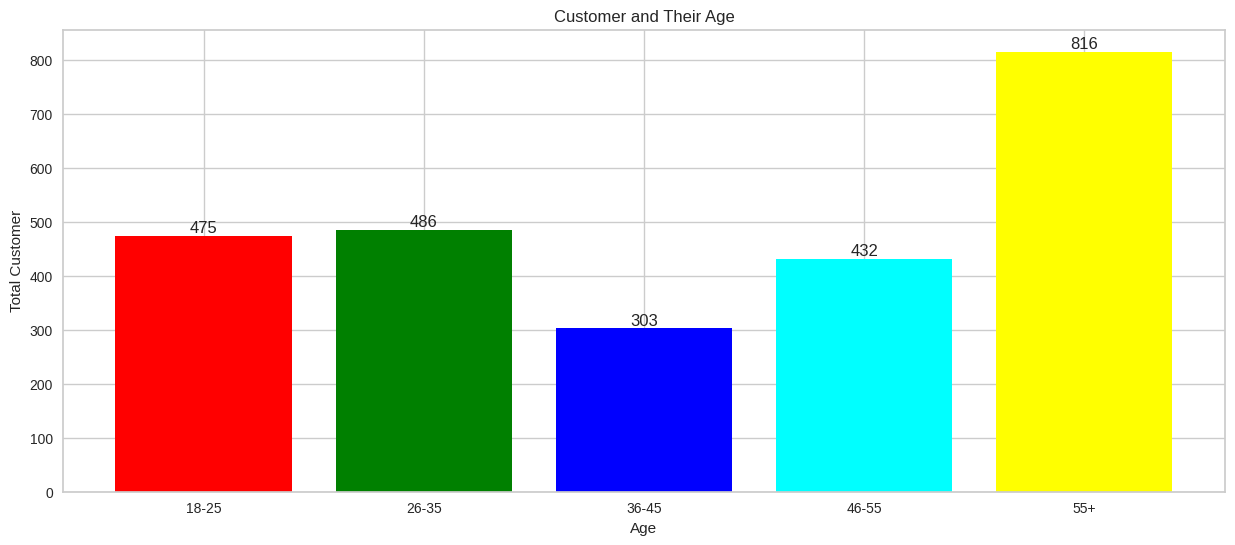

In [4]:
#4.2 Mengelompokkan usia pelanggan menggunakan binning
usia18_25 = df.CustomerAge[(df.CustomerAge >= 18) & (df.CustomerAge <= 25)]
usia26_35 = df.CustomerAge[(df.CustomerAge >= 26) & (df.CustomerAge <= 35)]
usia36_45 = df.CustomerAge[(df.CustomerAge >= 36) & (df.CustomerAge <= 45)]
usia46_55 = df.CustomerAge[(df.CustomerAge >= 46) & (df.CustomerAge <= 55)]
usia55keatas = df.CustomerAge[df.CustomerAge >= 56]

x = ["18-25", "26-35", "36-45", "46-55", "55+"]
y = [len(usia18_25.values), len(usia26_35.values), len(usia36_45.values), len(usia46_55.values), len(usia55keatas.values)]

plt.figure(figsize=(15, 6))
plt.bar(x, y, color=['red', 'green', 'blue', 'cyan', 'yellow'])
plt.title("Customer and Their Age")
plt.xlabel("Age")
plt.ylabel("Total Customer")

for i in range(len(x)):
    plt.text(i, y[i], y[i], ha='center', va='bottom')

plt.show()

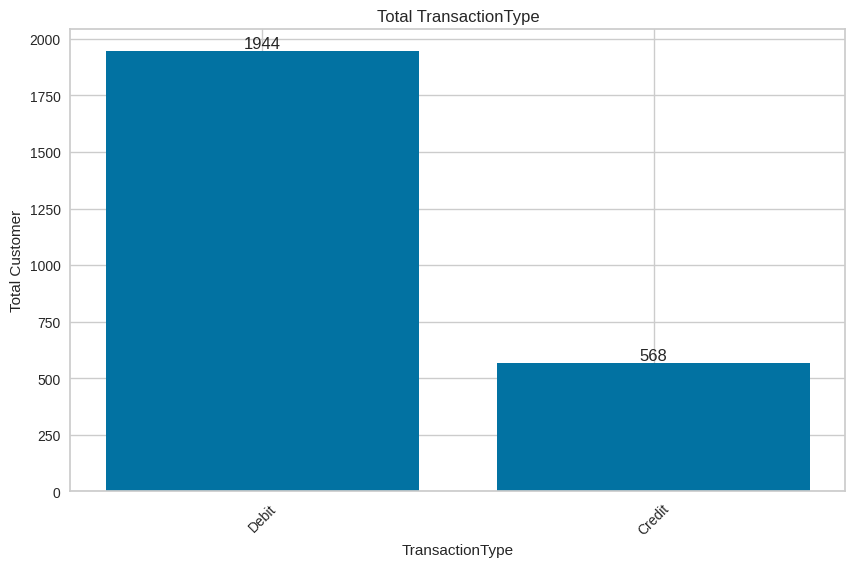

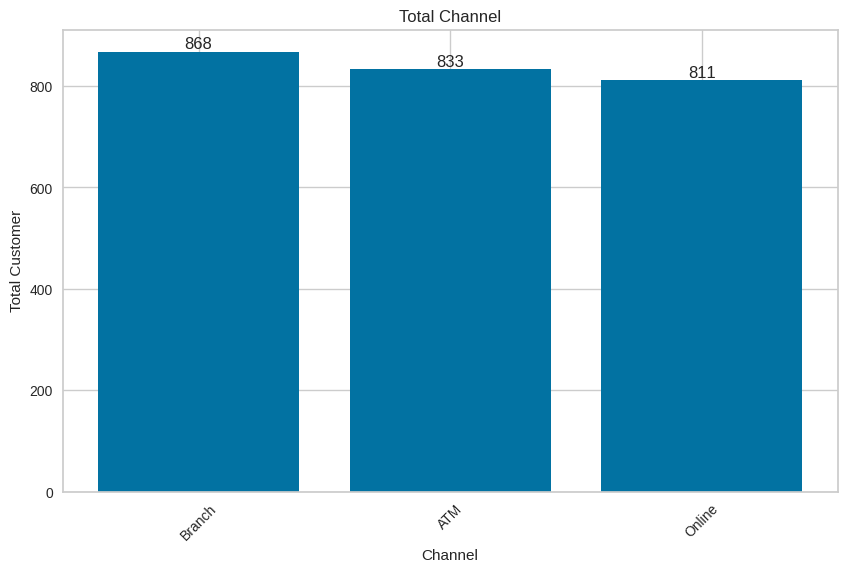

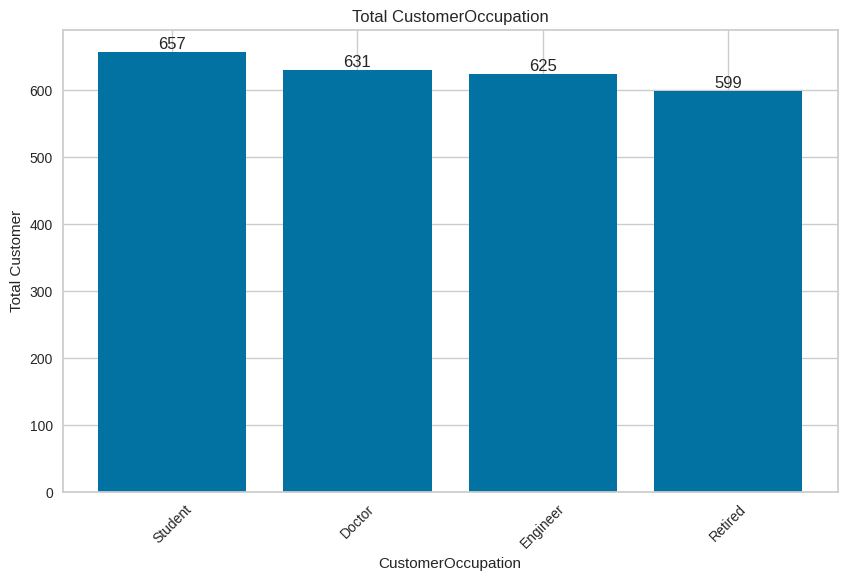

In [5]:
#4.3 Mengelompokkan pelanggan berdasarkan variabel kategorikal
variabel_kategorikal = ['TransactionType', 'Channel', 'CustomerOccupation']

for var in variabel_kategorikal:
    total = df[var].value_counts()
    kategori = total.index.tolist()
    total_customer = total.values.tolist()

    plt.figure(figsize=(10, 6))

    plt.bar(kategori, total_customer)
    plt.title(f'Total {var}')
    plt.xlabel(var)
    plt.ylabel('Total Customer')
    plt.xticks(rotation=45)

    for i, freq in enumerate(total_customer):
        plt.text(i, freq, str(freq), ha='center', va='bottom')

    plt.show()

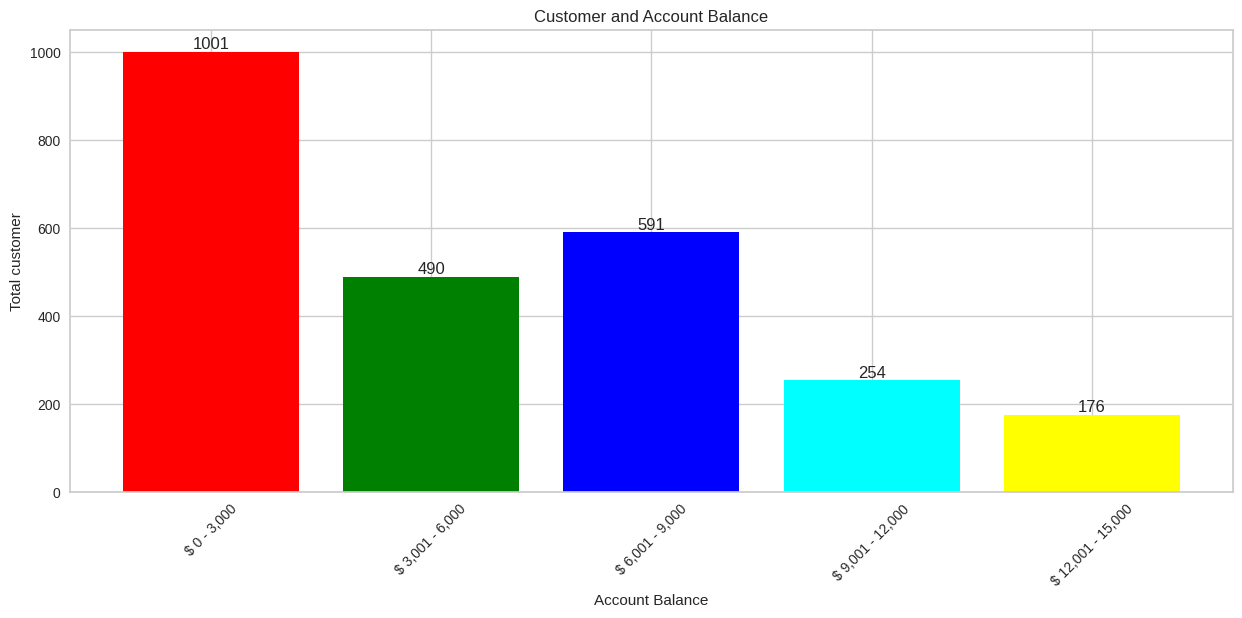

In [6]:
#4.4 Mengelompokkan saldo akun pelanggan
ai0_3000 = df['AccountBalance'][(df["AccountBalance"] >= 0) & (df["AccountBalance"] <= 3000)]
ai3001_6000 = df["AccountBalance"][(df["AccountBalance"] >= 3001) & (df["AccountBalance"] <= 6000)]
ai6001_9000 = df["AccountBalance"][(df["AccountBalance"] >= 6001) & (df["AccountBalance"] <= 9000)]
ai9001_12000 = df["AccountBalance"][(df["AccountBalance"] >= 9001) & (df["AccountBalance"] <= 12000)]
ai12001_15000 = df["AccountBalance"][(df["AccountBalance"] >= 12001) & (df["AccountBalance"] <= 15000)]

aix = ["$ 0 - 3,000", "$ 3,001 - 6,000", "$ 6,001 - 9,000", "$ 9,001 - 12,000", "$ 12,001 - 15,000"]
aiy = [len(ai0_3000.values), len(ai3001_6000.values), len(ai6001_9000.values), len(ai9001_12000.values), len(ai12001_15000.values)]

plt.figure(figsize=(15, 6))
plt.bar(aix, aiy, color=['red', 'green', 'blue', 'cyan', 'yellow'])
plt.title("Customer and Account Balance")
plt.xlabel("Account Balance")
plt.ylabel("Total customer")
plt.xticks(rotation=45)

for i in range(len(aix)):
    plt.text(i, aiy[i], aiy[i], ha='center', va='bottom')

plt.show()

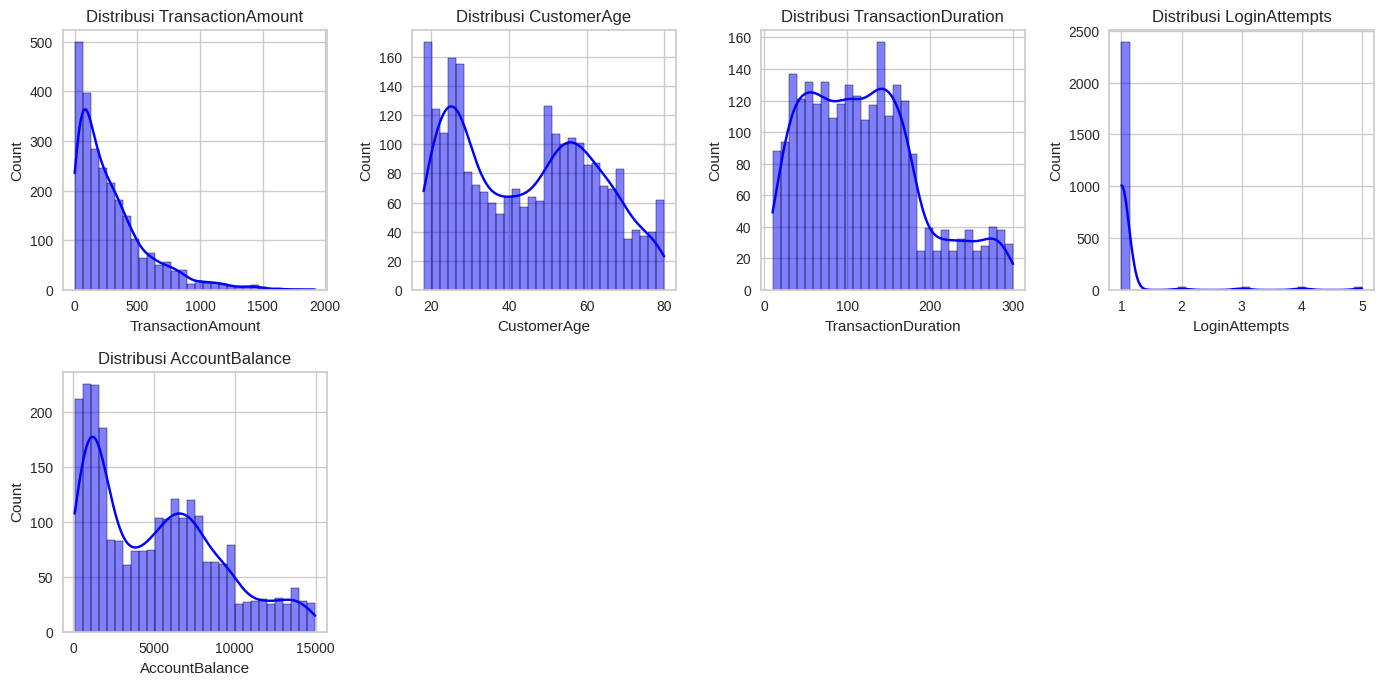

In [7]:
#4.5 Visualisasi Distribusi Fitur Numerik
fitur_numerik = df.select_dtypes(include=[np.number])
plt.figure(figsize=(14, 10))
for i, kolom in enumerate(fitur_numerik.columns, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df[kolom], bins=30, kde=True, color='blue')
    plt.title(f'Distribusi {kolom}')
plt.tight_layout()
plt.show()

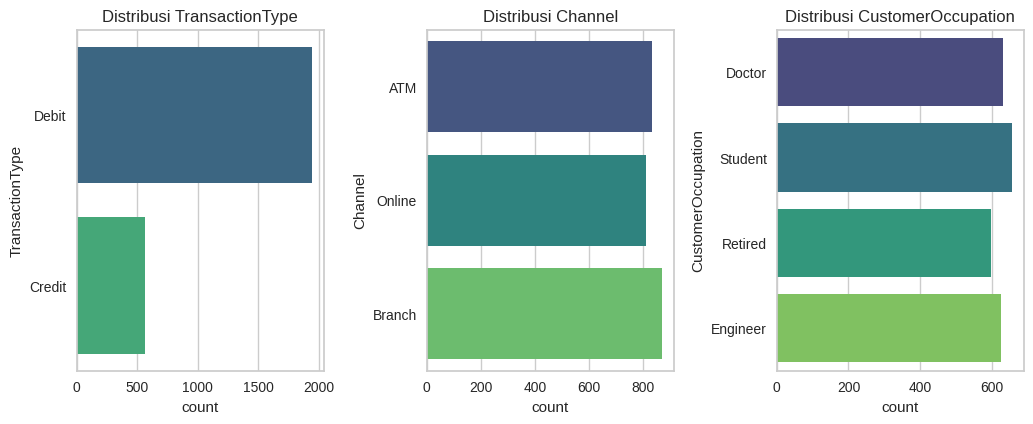

In [8]:
#4.6 Visualisasi Distribusi Fitur Kategorikal
plt.figure(figsize=(14, 8))
for i, kolom in enumerate(variabel_kategorikal, 1):
    plt.subplot(2, 4, i)
    sns.countplot(y=df[kolom], hue=df[kolom], palette='viridis', legend=False)
    plt.title(f'Distribusi {kolom}')
plt.tight_layout()
plt.show()

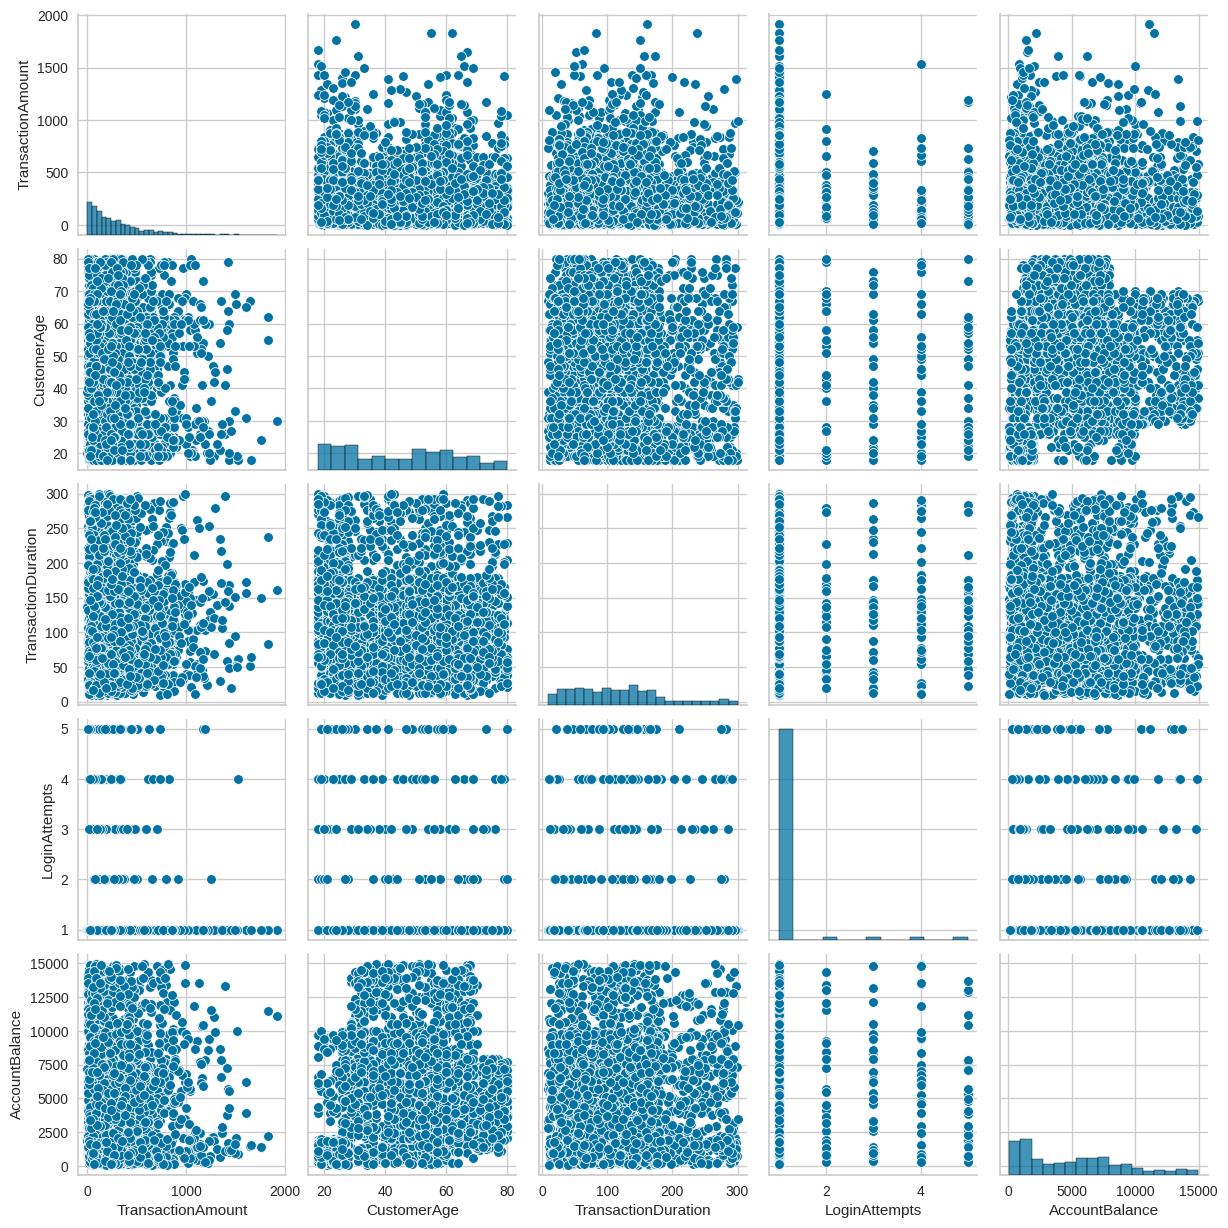

In [9]:
#4.7 Visualisasi Hubungan Antar Fitur Numerik dengan Pairplot
sns.pairplot(fitur_numerik)
plt.show()

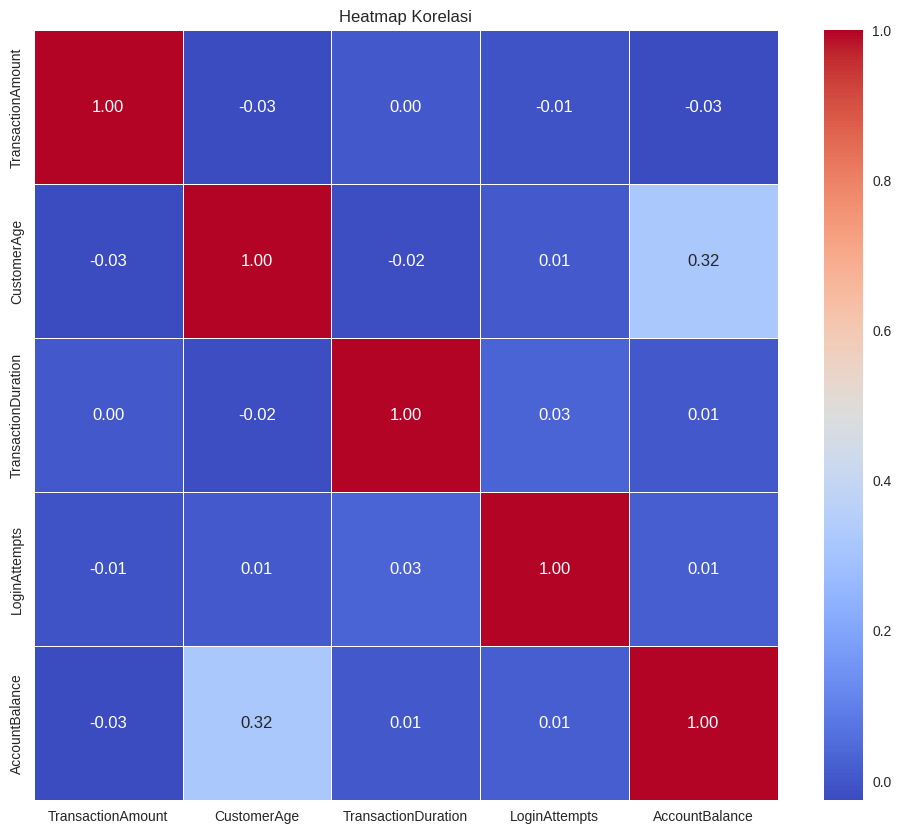

In [10]:
#4.8 Visualisasi Korelasi Antar Fitur Numerik dengan Heatmap
plt.figure(figsize=(12, 10))
matriks_corellation = fitur_numerik.corr()
sns.heatmap(matriks_corellation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi')
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah.

In [11]:
#5.1 Menyalin dataframe df untuk preprocessing
df_preprocessed = df.copy()
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2512 non-null   object 
 1   AccountID                2512 non-null   object 
 2   TransactionAmount        2512 non-null   float64
 3   TransactionDate          2512 non-null   object 
 4   TransactionType          2512 non-null   object 
 5   Location                 2512 non-null   object 
 6   DeviceID                 2512 non-null   object 
 7   IP Address               2512 non-null   object 
 8   MerchantID               2512 non-null   object 
 9   Channel                  2512 non-null   object 
 10  CustomerAge              2512 non-null   int64  
 11  CustomerOccupation       2512 non-null   object 
 12  TransactionDuration      2512 non-null   int64  
 13  LoginAttempts            2512 non-null   int64  
 14  AccountBalance          

In [12]:
#5.2 Memeriksa duplikasi dan nilai yang hilang
duplikat = df_preprocessed.duplicated().sum()
print(f"Jumlah baris duplikat: {duplikat}")

nilai_hilang = df_preprocessed.isnull().sum()
print("Nilai yang hilang di setiap kolom:")
print(nilai_hilang)

Jumlah baris duplikat: 0
Nilai yang hilang di setiap kolom:
TransactionID              0
AccountID                  0
TransactionAmount          0
TransactionDate            0
TransactionType            0
Location                   0
DeviceID                   0
IP Address                 0
MerchantID                 0
Channel                    0
CustomerAge                0
CustomerOccupation         0
TransactionDuration        0
LoginAttempts              0
AccountBalance             0
PreviousTransactionDate    0
dtype: int64


In [13]:
#5.3 Mengubah tipe data dari object menjadi datetime
kolom_yang_dibutuhkan = ['TransactionDate', 'PreviousTransactionDate']
for kolom in kolom_yang_dibutuhkan:
    df_preprocessed[kolom] = pd.to_datetime(df_preprocessed[kolom])
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionID            2512 non-null   object        
 1   AccountID                2512 non-null   object        
 2   TransactionAmount        2512 non-null   float64       
 3   TransactionDate          2512 non-null   datetime64[ns]
 4   TransactionType          2512 non-null   object        
 5   Location                 2512 non-null   object        
 6   DeviceID                 2512 non-null   object        
 7   IP Address               2512 non-null   object        
 8   MerchantID               2512 non-null   object        
 9   Channel                  2512 non-null   object        
 10  CustomerAge              2512 non-null   int64         
 11  CustomerOccupation       2512 non-null   object        
 12  TransactionDuration      2512 non-

In [14]:
#5.4 Menghapus kolom yang tidak digunakan
kolom_dihapus = ['TransactionID', 'AccountID', 'DeviceID', 'IP Address', 'MerchantID', 'LoginAttempts']
df_preprocessed.drop(columns=kolom_dihapus, inplace=True)
df_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   TransactionAmount        2512 non-null   float64       
 1   TransactionDate          2512 non-null   datetime64[ns]
 2   TransactionType          2512 non-null   object        
 3   Location                 2512 non-null   object        
 4   Channel                  2512 non-null   object        
 5   CustomerAge              2512 non-null   int64         
 6   CustomerOccupation       2512 non-null   object        
 7   TransactionDuration      2512 non-null   int64         
 8   AccountBalance           2512 non-null   float64       
 9   PreviousTransactionDate  2512 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(2), object(4)
memory usage: 196.4+ KB


In [15]:
#5.5 Menambahkan kolom hari antara transaksi terakhir
df_preprocessed["DayFromTransaction"] = (df_preprocessed["PreviousTransactionDate"] - df_preprocessed["TransactionDate"]).dt.days
df_preprocessed.head()

,TransactionAmount,TransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,AccountBalance,PreviousTransactionDate,DayFromTransaction
0,14.09,2023-04-11 16:29:14,Debit,San Diego,ATM,70,Doctor,81,5112.21,2024-11-04 08:08:08,572
1,376.24,2023-06-27 16:44:19,Debit,Houston,ATM,68,Doctor,141,13758.91,2024-11-04 08:09:35,495
2,126.29,2023-07-10 18:16:08,Debit,Mesa,Online,19,Student,56,1122.35,2024-11-04 08:07:04,482
3,184.50,2023-05-05 16:32:11,Debit,Raleigh,Online,26,Student,25,8569.06,2024-11-04 08:09:06,548
4,13.45,2023-10-16 17:51:24,Credit,Atlanta,Online,26,Student,198,7429.40,2024-11-04 08:06:39,384


In [16]:
#5.6 Semua fitur numerik
fitur_numerik = df_preprocessed.select_dtypes(include=['number']).columns
print(fitur_numerik)

Index(['TransactionAmount', 'CustomerAge', 'TransactionDuration',
       'AccountBalance', 'DayFromTransaction'],
      dtype='object')


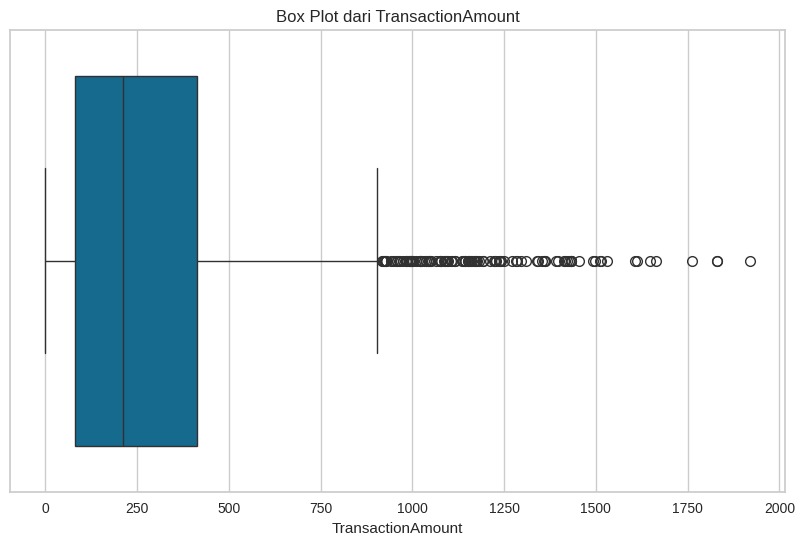

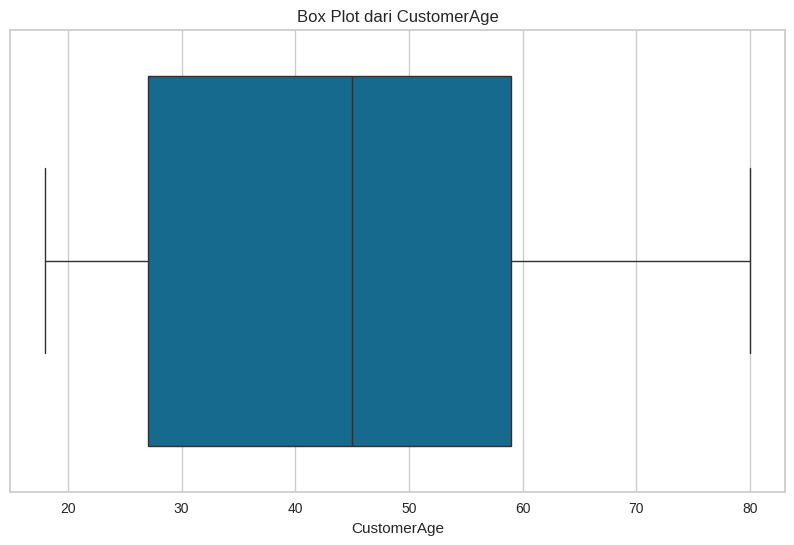

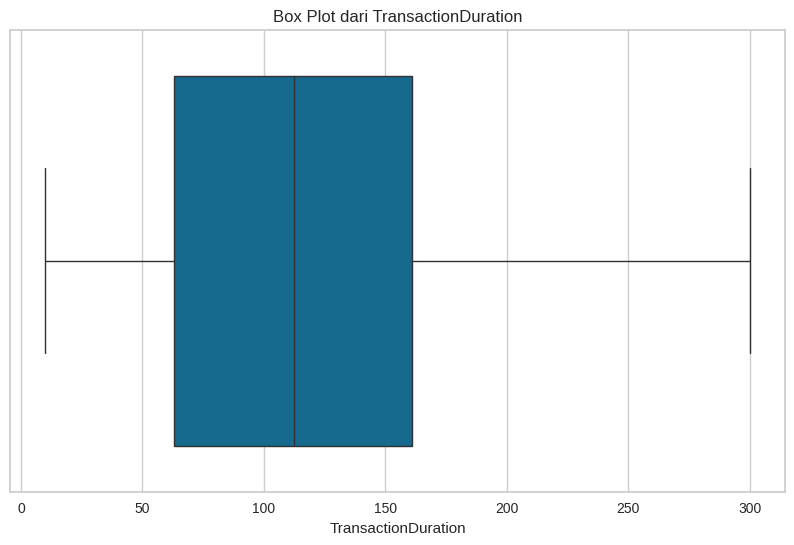

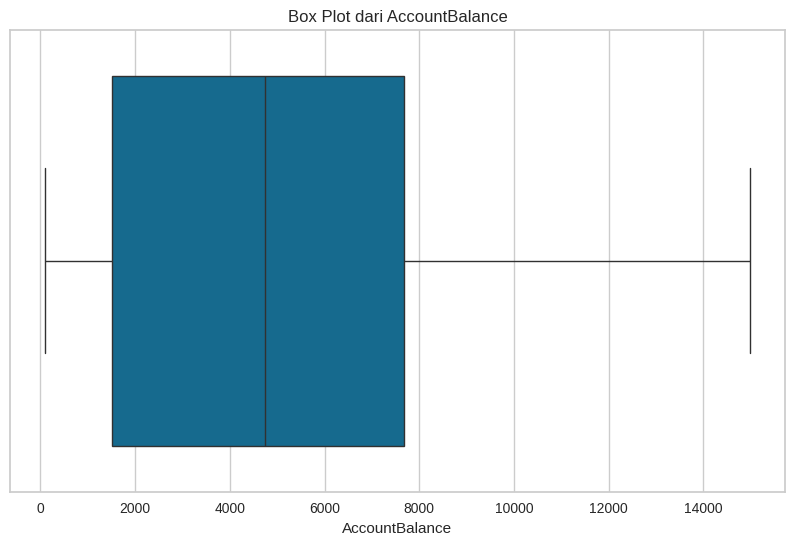

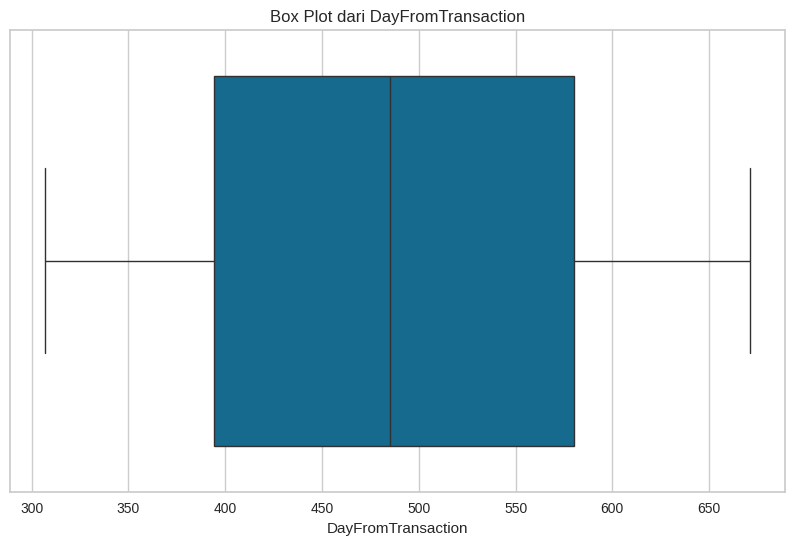

In [17]:
#5.7 Membuat plot untuk mendeteksi outlier
for fitur in fitur_numerik:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df_preprocessed[fitur])
    plt.title(f'Box Plot dari {fitur}')
    plt.show()

In [18]:
#5.8 Menangani outlier
for fitur in fitur_numerik:
    Q1 = df_preprocessed[fitur].quantile(0.25)
    Q3 = df_preprocessed[fitur].quantile(0.75)
    IQR = Q3 - Q1

    if fitur not in ['TransactionAmount', 'AccountBalance']:
        batas_bawah = Q1 - 1.5 * IQR
        batas_atas = Q3 + 1.5 * IQR
        df_preprocessed = df_preprocessed[(df_preprocessed[fitur] >= batas_bawah) & (df_preprocessed[fitur] <= batas_atas)]

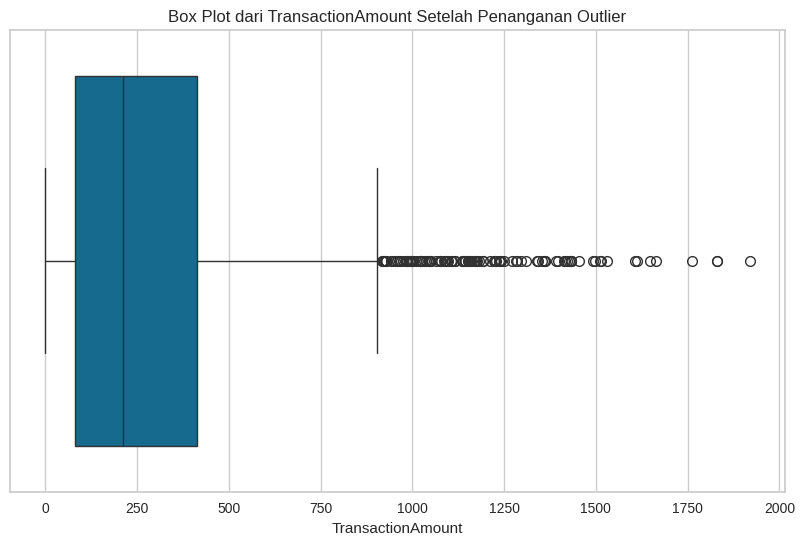

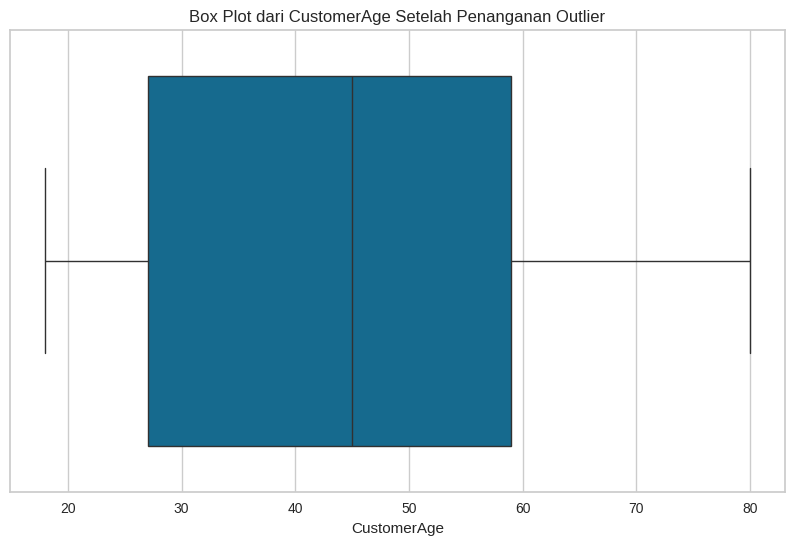

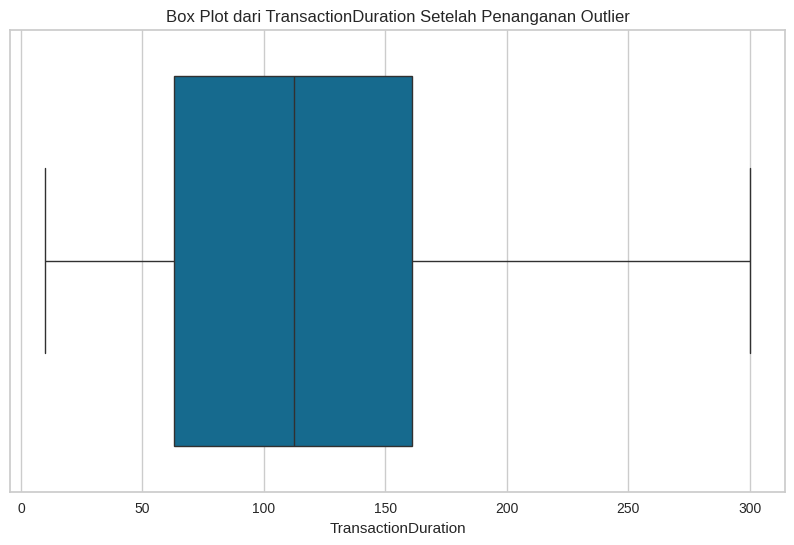

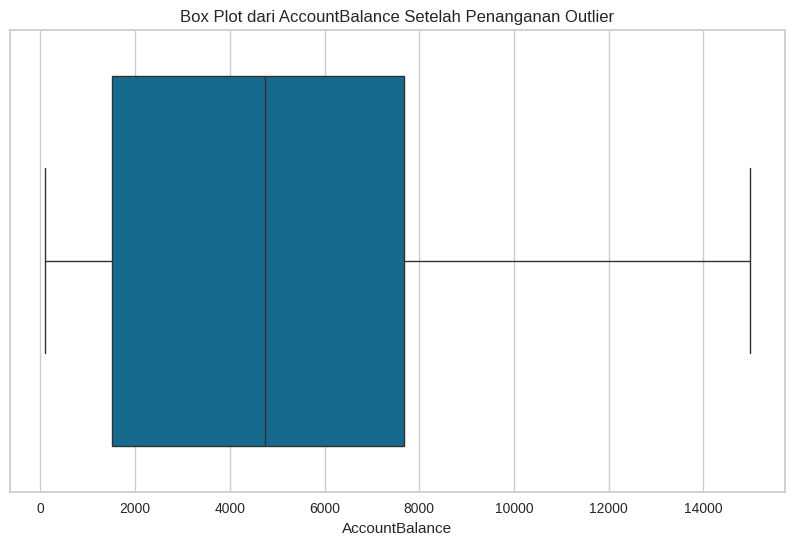

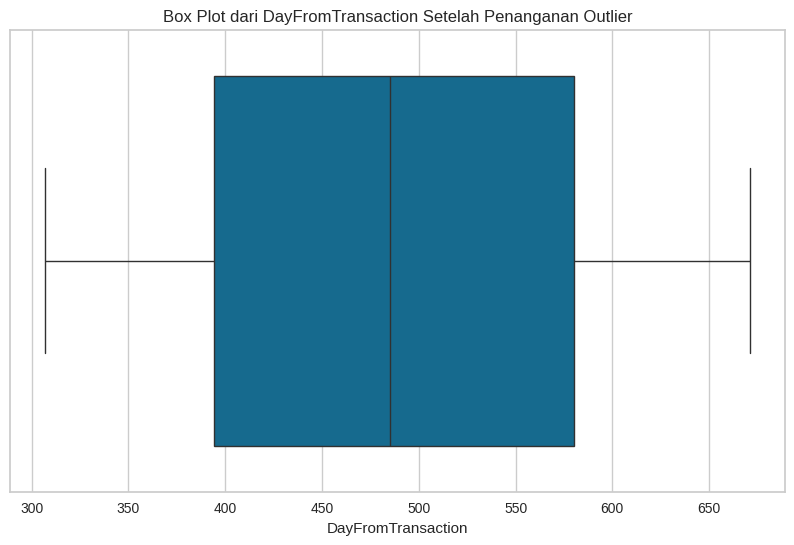

In [19]:
#5.9 Melakukan plotting boxplot setelah penanganan outlier
for fitur in fitur_numerik:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df_preprocessed[fitur])
    plt.title(f'Box Plot dari {fitur} Setelah Penanganan Outlier')
    plt.show()

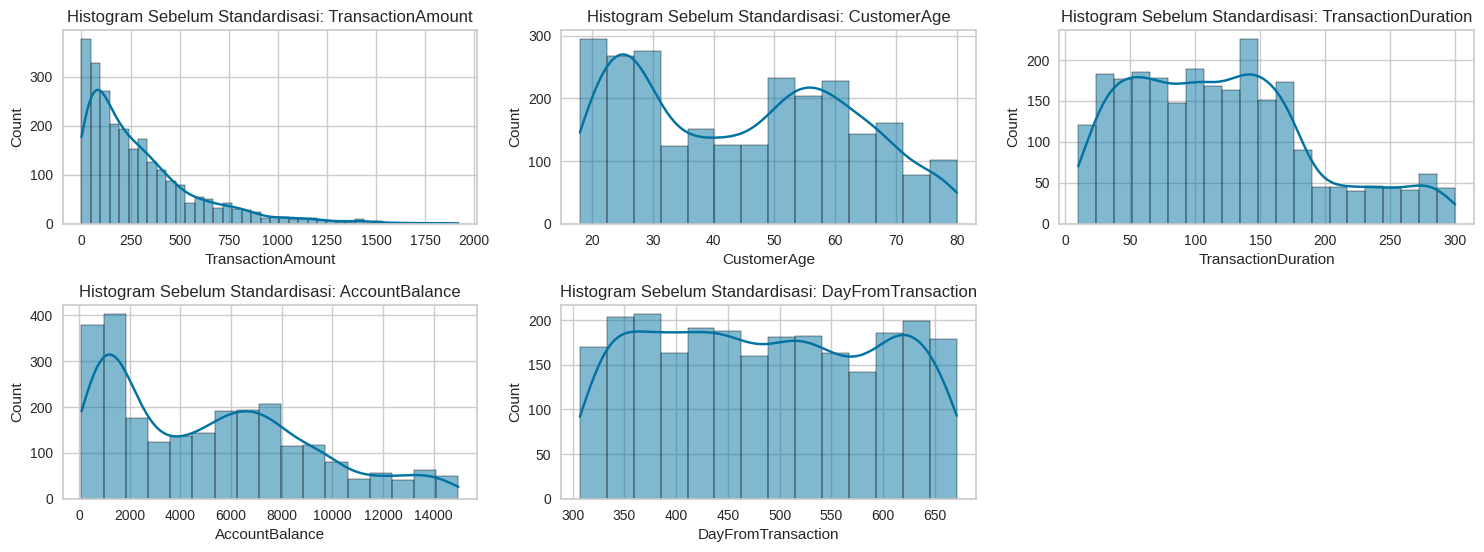

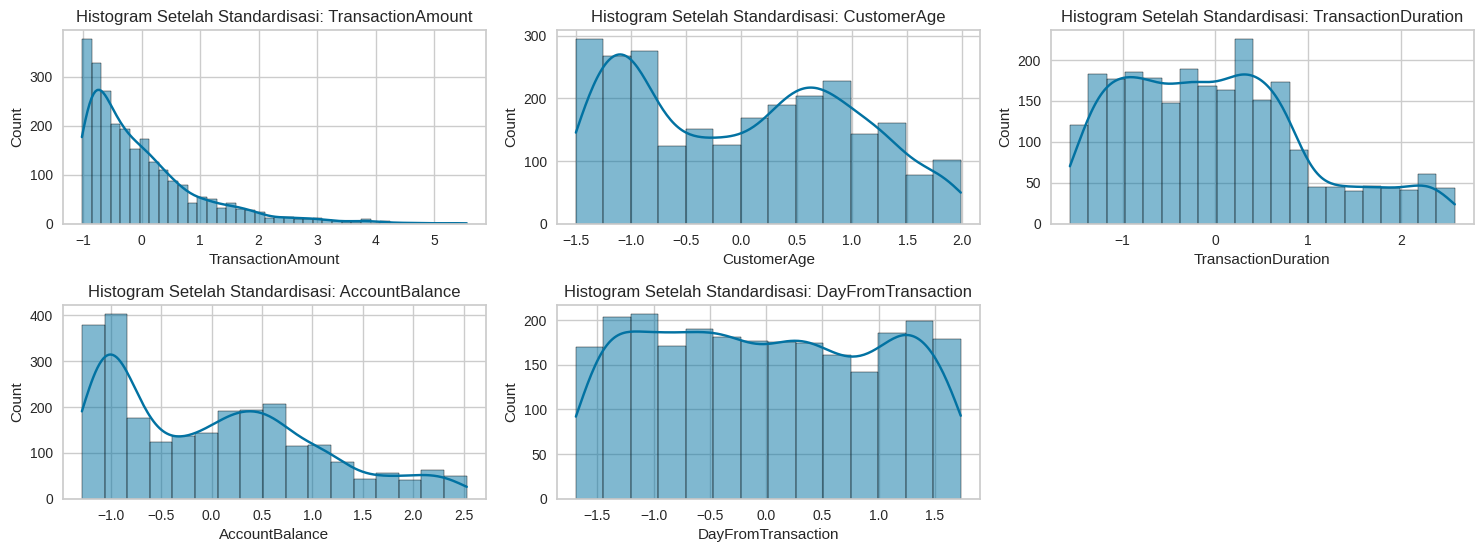

In [20]:
#5.10 Histogram sebelum dan sesudah standardisasi
plt.figure(figsize=(15, 8))
for i, fitur in enumerate(fitur_numerik):
    plt.subplot(3, 3, i+1)
    sns.histplot(df_preprocessed[fitur], kde=True)
    plt.title(f"Histogram Sebelum Standardisasi: {fitur}")
plt.tight_layout()
plt.show()

# Standarisasi
scaler = StandardScaler()
df_preprocessed[fitur_numerik] = scaler.fit_transform(df_preprocessed[fitur_numerik])

plt.figure(figsize=(15, 8))
for i, fitur in enumerate(fitur_numerik):
    plt.subplot(3, 3, i+1)
    sns.histplot(df_preprocessed[fitur], kde=True)
    plt.title(f"Histogram Setelah Standardisasi: {fitur}")
plt.tight_layout()
plt.show()


In [21]:
#5.11 Label Encoding
fitur_kategorikal = df_preprocessed.select_dtypes(include=['object']).columns
print(f"Fitur Kategorikal:\n{fitur_kategorikal}")

print("Sebelum Label Encoding:")
print(df_preprocessed[fitur_kategorikal].head())

label_encoders = {}
df_lencoder = df_preprocessed.copy()
for kolom in fitur_kategorikal:
    label_encoders[kolom] = LabelEncoder()
    df_lencoder[kolom] = label_encoders[kolom].fit_transform(df_lencoder[kolom])

print("Setelah Label Encoding:")
print(df_lencoder[fitur_kategorikal].head())


Fitur Kategorikal:
Index(['TransactionType', 'Location', 'Channel', 'CustomerOccupation'], dtype='object')
Sebelum Label Encoding:
  TransactionType   Location Channel CustomerOccupation
0           Debit  San Diego     ATM             Doctor
1           Debit    Houston     ATM             Doctor
2           Debit       Mesa  Online            Student
3           Debit    Raleigh  Online            Student
4          Credit    Atlanta  Online            Student
Setelah Label Encoding:
   TransactionType  Location  Channel  CustomerOccupation
0                1        36        0                   0
1                1        15        0                   0
2                1        23        2                   3
3                1        33        2                   3
4                0         1        2                   3


In [60]:
#5.12 Menyimpan data akhir untuk clustering
fitur_clustering = ['TransactionAmount', 'AccountBalance', 'CustomerAge',
                    'CustomerOccupation', 'DayFromTransaction', 'Channel',
                    'TransactionType', 'Location', 'TransactionDuration']

df_final_clustering = df_lencoder[fitur_clustering].copy()




# **6. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan. Berikut adalah **rekomendasi** tahapannya.
1. Pilih algoritma clustering yang sesuai.
2. Latih model dengan data menggunakan algoritma tersebut.

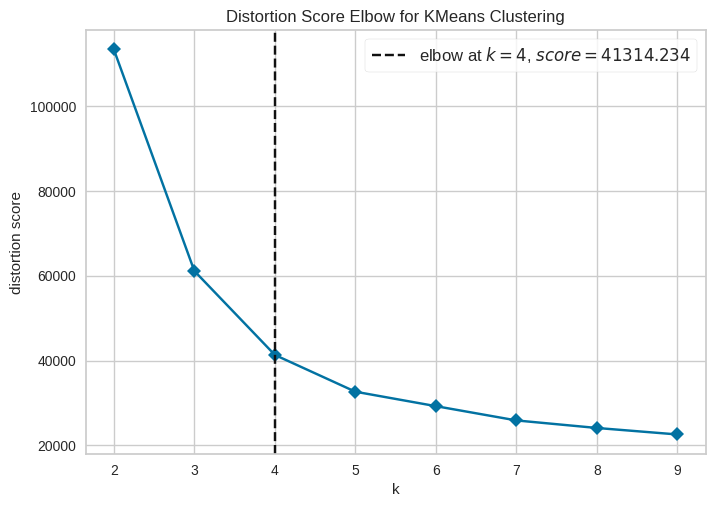

Jumlah cluster optimal berdasarkan metode Elbow: 4


In [61]:
fitur_terstandarisasi = df_final_clustering.copy()


kmeans = KMeans(random_state=42)
visualizer = KElbowVisualizer(kmeans, k=(2, 10), metric='distortion', timings=False)
visualizer.fit(fitur_terstandarisasi)
visualizer.show()

optimal_clusters = visualizer.elbow_value_
print(f"Jumlah cluster optimal berdasarkan metode Elbow: {optimal_clusters}")

In [62]:
model_kmeans = KMeans(n_clusters=optimal_clusters, random_state=0)
model_kmeans.fit(fitur_terstandarisasi)

cluster_labels = model_kmeans.labels_

# Simpan cluster ke df_lencoder (data akhir preprocessing)
df_lencoder['Cluster'] = cluster_labels
print(df_lencoder['Cluster'].value_counts())

Cluster
1    689
2    656
3    590
0    577
Name: count, dtype: int64


## **b. Evaluasi Model Clustering**

Untuk menentukan jumlah cluster yang optimal dalam model clustering, Anda dapat menggunakan metode Elbow atau Silhouette Score.

Metode ini membantu kita menemukan jumlah cluster yang memberikan pemisahan terbaik antar kelompok data, sehingga model yang dibangun dapat lebih efektif. Berikut adalah **rekomendasi** tahapannya.
1. Gunakan Silhouette Score dan Elbow Method untuk menentukan jumlah cluster optimal.
2. Hitung Silhouette Score sebagai ukuran kualitas cluster.

In [63]:
silhouette_avg = silhouette_score(fitur_terstandarisasi, cluster_labels)
print(f"Silhouette Score: {silhouette_avg}")

# Silhouette per observasi
silhouette_values = silhouette_samples(fitur_terstandarisasi, cluster_labels)
df_lencoder['Silhouette Score'] = silhouette_values

# Rata-rata Silhouette per cluster
print(df_lencoder.groupby('Cluster')['Silhouette Score'].mean())

Silhouette Score: 0.43721977541850904
Cluster
0    0.488783
1    0.490342
2    0.374388
3    0.394617
Name: Silhouette Score, dtype: float64


## **c. Feature Selection (Opsional)**

Silakan lakukan feature selection jika Anda membutuhkan optimasi model clustering. Jika Anda menerapkan proses ini, silakan lakukan pemodelan dan evaluasi kembali menggunakan kolom-kolom hasil feature selection. Terakhir, bandingkan hasil performa model sebelum dan sesudah menerapkan feature selection.

Fitur yang Terpilih: Index(['CustomerAge', 'Channel', 'TransactionType', 'Location',
       'TransactionDuration'],
      dtype='object')


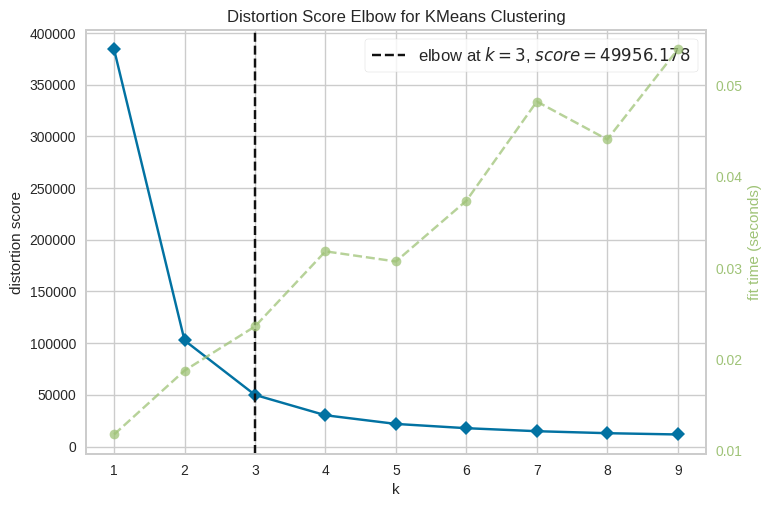

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [64]:
model_rfe = LogisticRegression(max_iter=1000)
rfe_selector = RFE(model_rfe, n_features_to_select=5)
rfe_selector.fit(fitur_terstandarisasi, cluster_labels)

selected_features_from_rfe = df_final_clustering.columns[rfe_selector.get_support(indices=True)]
print("Fitur yang Terpilih:", selected_features_from_rfe)

# Evaluasi ulang dengan fitur hasil seleksi
kmeans_rfe = KMeans(n_init=10, random_state=42)
visualizer_rfe = KElbowVisualizer(kmeans_rfe, k=(1, 10))
visualizer_rfe.fit(df_final_clustering[selected_features_from_rfe])
visualizer_rfe.show()



In [67]:
# Model baru dengan fitur hasil seleksi
model_kmeans_rfe = KMeans(n_clusters=3, random_state=0)
model_kmeans_rfe.fit(df_final_clustering[selected_features_from_rfe])
cluster_labels_rfe = model_kmeans_rfe.labels_

silhouette_avg_rfe = silhouette_score(df_final_clustering[selected_features_from_rfe], cluster_labels_rfe)
print(f"Silhouette Score sebelum Seleksi Fitur: {silhouette_avg}")
print(f"Silhouette Score setelah Seleksi Fitur: {silhouette_avg_rfe}")

Silhouette Score sebelum Seleksi Fitur: 0.43721977541850904
Silhouette Score setelah Seleksi Fitur: 0.5359496816990494


## **d. Visualisasi Hasil Clustering**

Setelah model clustering dilatih dan jumlah cluster optimal ditentukan, langkah selanjutnya adalah menampilkan hasil clustering melalui visualisasi.

Berikut adalah **rekomendasi** tahapannya.
1. Tampilkan hasil clustering dalam bentuk visualisasi, seperti grafik scatter plot atau 2D PCA projection.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


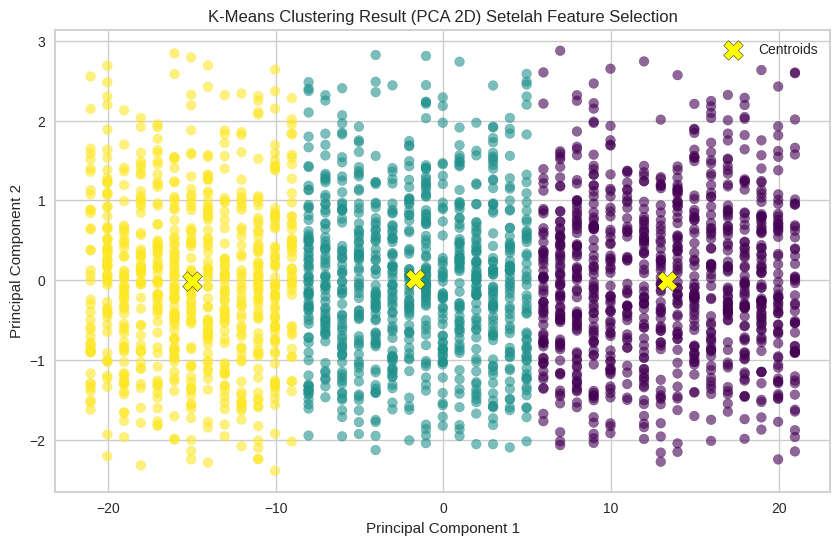

In [68]:
# pca
pca = PCA(n_components=2)
fitur_pca = pca.fit_transform(df_final_clustering[selected_features_from_rfe])

# Gunakan centroid dari model yang sudah dilatih
centroids = model_kmeans_rfe.cluster_centers_
centroids_pca = pca.transform(centroids)

# Visualisasi scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(fitur_pca[:, 0], fitur_pca[:, 1], c=cluster_labels_rfe, cmap='viridis', alpha=0.6)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='yellow', marker='X', s=200, label='Centroids', edgecolors='black')

plt.title('K-Means Clustering Result (PCA 2D) Setelah Feature Selection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(loc='best')
plt.grid(True)
plt.show()


## **e. Analisis dan Interpretasi Hasil Cluster**

### Interpretasi Target

**Tutorial: Melakukan Inverse Transform pada Data Target Setelah Clustering**

Setelah melakukan clustering dengan model **KMeans**, kita perlu mengembalikan data yang telah diubah (normalisasi, standarisasi, atau label encoding) ke bentuk aslinya. Berikut adalah langkah-langkahnya.

---

**1. Tambahkan Hasil Label Cluster ke DataFrame**
Setelah mendapatkan hasil clustering, kita tambahkan label cluster ke dalam DataFrame yang telah dinormalisasi.

```python
df_normalized['Cluster'] = model_kmeans.labels_
```

Lakukan Inverse Transform pada feature yang sudah dilakukan Labelisasi dan Standararisasi. Berikut code untuk melakukannya:
label_encoder.inverse_transform(X_Selected[['Fitur']])

Lalu masukkan ke dalam kolom dataset asli atau membuat dataframe baru
```python
df_normalized['Fitur'] = label_encoder.inverse_transform(df_normalized[['Fitur']])
```
Masukkan Data yang Sudah Di-Inverse ke dalam Dataset Asli atau Buat DataFrame Baru
```python
df_original['Fitur'] = df_normalized['Fitur']
```

In [69]:
# Salin data asli
df_analisis = df.copy()

# Get cluster labels using the selected features and the trained model
cluster_labels = model_kmeans_rfe.predict(df_final_clustering[selected_features_from_rfe])

# Tambahkan label cluster hasil dari model optimal
df_analisis['Cluster'] = cluster_labels

### Inverse Data Jika Melakukan Normalisasi/Standardisasi

Inverse Transform untuk Data yang Distandarisasi
Jika data numerik telah dinormalisasi menggunakan StandardScaler atau MinMaxScaler, kita bisa mengembalikannya ke skala asli:
```python
df_normalized[['Fitur_Numerik']] = scaler.inverse_transform(df_normalized[['Fitur_Numerik']])
```

In [70]:
#Sayaa menggunakan data asli lalu label hasil clustering optimal saya masukkan

Setelah melakukan clustering, langkah selanjutnya adalah menganalisis karakteristik dari masing-masing cluster berdasarkan fitur yang tersedia.

Berikut adalah **rekomendasi** tahapannya.
1. Analisis karakteristik tiap cluster berdasarkan fitur yang tersedia (misalnya, distribusi nilai dalam cluster).
2. Berikan interpretasi: Apakah hasil clustering sesuai dengan ekspektasi dan logika bisnis? Apakah ada pola tertentu yang bisa dimanfaatkan?

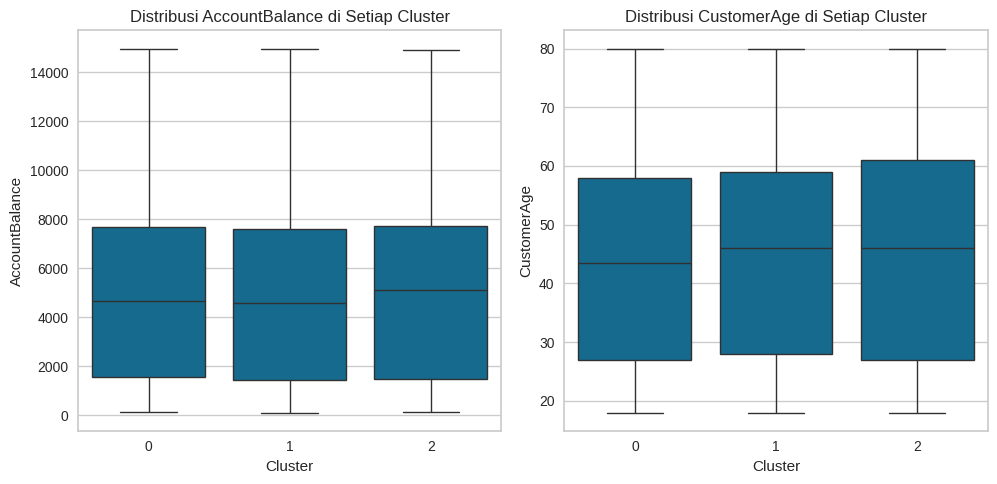

In [71]:
#Visualisasi fitur numerik berdasarkan data asli
fitur_numerik_terpilih = ['AccountBalance', 'CustomerAge']

plt.figure(figsize=(15, 5))

for i, fitur in enumerate(fitur_numerik_terpilih):
    plt.subplot(1, 3, i+1)
    sns.boxplot(x='Cluster', y=fitur, data=df_analisis)
    plt.title(f'Distribusi {fitur} di Setiap Cluster')

plt.tight_layout()
plt.show()


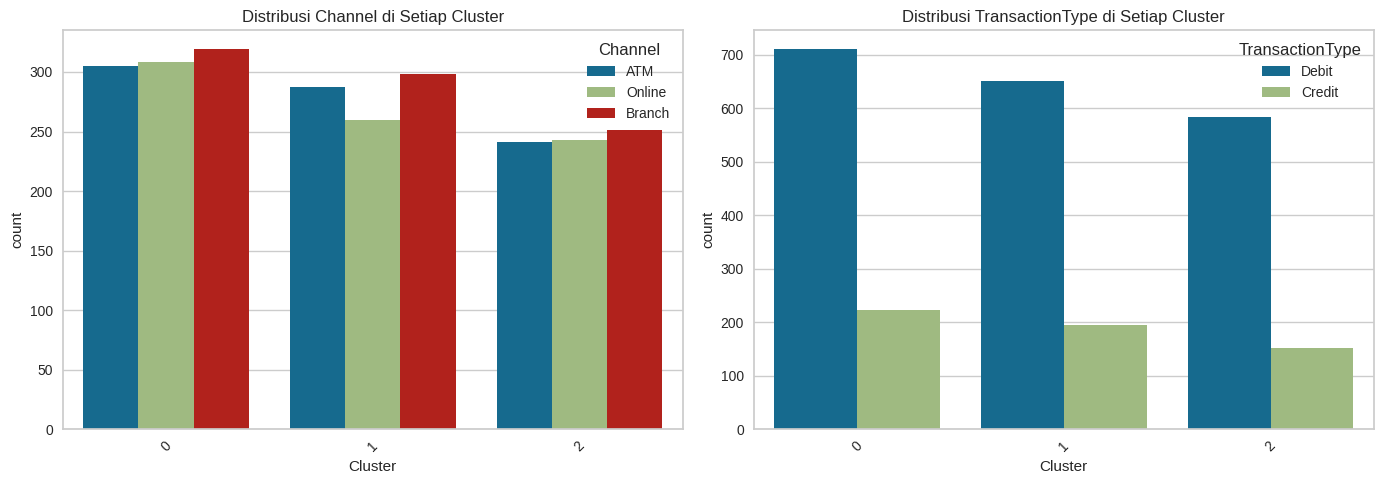

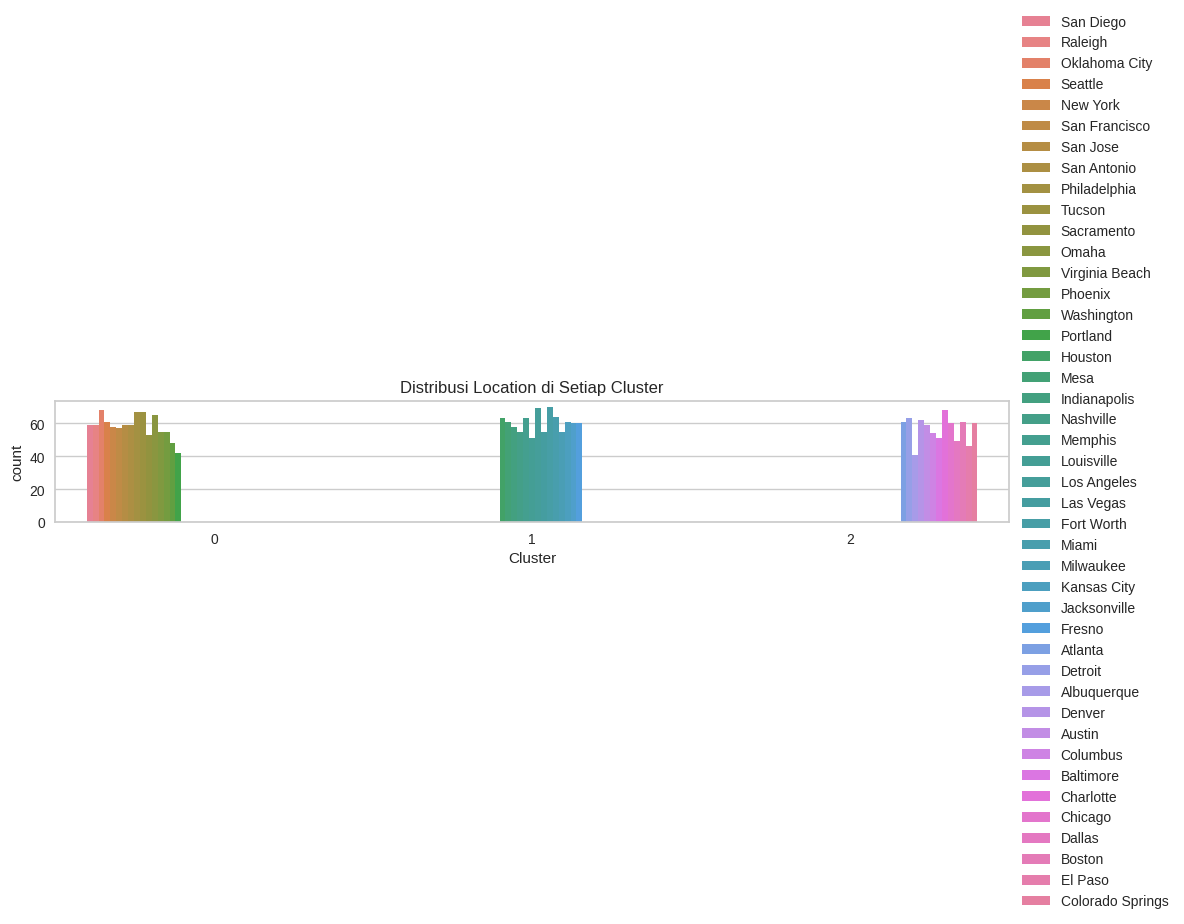

In [72]:
# Visualisasi fitur kategorikal berdasarkan data asli
# Plot 2 fitur kategorikal dulu: Channel & TransactionType
fitur_kategorikal_sederhana = ['Channel', 'TransactionType']

plt.figure(figsize=(14, 5))
for i, fitur in enumerate(fitur_kategorikal_sederhana):
    plt.subplot(1, 2, i+1)
    sns.countplot(x='Cluster', hue=fitur, data=df_analisis)
    plt.title(f'Distribusi {fitur} di Setiap Cluster')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot fitur Location secara terpisah
plt.figure(figsize=(12, 6))
sns.countplot(x='Cluster', hue='Location', data=df_analisis)
plt.title('Distribusi Location di Setiap Cluster')
plt.xticks(rotation=0)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)
plt.tight_layout()
plt.show()



In [73]:
# Fungsi untuk menganalisis karakteristik setiap cluster
k = visualizer_rfe.elbow_value_

# Fungsi untuk menganalisis karakteristik setiap cluster
def analisis_karakteristik_cluster(data, jumlah_cluster):
    print("Analisis Karakteristik Cluster:")
    for id_cluster in range(jumlah_cluster):
        cluster_data = data[data['Cluster'] == id_cluster]

        rata_rata_saldo = cluster_data['AccountBalance'].mean()
        rata_rata_usia = cluster_data['CustomerAge'].mean()
        modus_channel = cluster_data['Channel'].mode()[0]
        modus_transaksi = cluster_data['TransactionType'].mode()[0]
        modus_lokasi = cluster_data['Location'].mode()[0]

        print(f"\nCluster {id_cluster + 1}:")
        print(f"Rata-rata Saldo Akun: {rata_rata_saldo:.2f}")
        print(f"Rata-rata Usia Pelanggan: {rata_rata_usia:.2f}")
        print(f"Modus Channel: {modus_channel}")
        print(f"Modus Jenis Transaksi: {modus_transaksi}")
        print(f"Modus Lokasi: {modus_lokasi}")

# Jalankan analisis dengan data df_analisis
analisis_karakteristik_cluster(df_analisis, jumlah_cluster=k)

Analisis Karakteristik Cluster:

Cluster 1:
Rata-rata Saldo Akun: 5139.51
Rata-rata Usia Pelanggan: 44.17
Modus Channel: Branch
Modus Jenis Transaksi: Debit
Modus Lokasi: Oklahoma City

Cluster 2:
Rata-rata Saldo Akun: 5052.46
Rata-rata Usia Pelanggan: 44.84
Modus Channel: Branch
Modus Jenis Transaksi: Debit
Modus Lokasi: Fort Worth

Cluster 3:
Rata-rata Saldo Akun: 5153.44
Rata-rata Usia Pelanggan: 45.13
Modus Channel: Branch
Modus Jenis Transaksi: Debit
Modus Lokasi: Charlotte


Tulis hasil interpretasinya di sini.
1. Cluster 1:
  *   Rata-rata Saldo Akun: 5139.51
  *   Rata-rata Usia Pelanggan: 44.17
  *   Modus Channel: Branch
  *   Modus Jenis Transaksi: Debit
  *   Modus Lokasi: Oklahoma City

      Analisis:
      Cluster ini terdiri dari pelanggan dengan saldo akun menengah dan usia yang sedikit lebih muda dibandingkan cluster lainnya. Mayoritas transaksi dilakukan melalui Branch dengan metode debit. Lokasi transaksi yang paling umum adalah Oklahoma City.

2. Cluster 2:
  *   Rata-rata Saldo Akun: 5052.46
  *   Rata-rata Usia Pelanggan: 44.84
  *   Modus Channel: Branch
  *   Modus Jenis Transaksi: Debit
  *   Modus Lokasi: Fort Worth

      Analisis:
      Cluster ini menunjukkan kelompok pelanggan dengan saldo akun yang sedikit lebih rendah dari Cluster 1. Usia pelanggan juga berada pada rentang yang hampir sama. Sebagian besar transaksi dilakukan melalui Branch, menggunakan metode debit, dengan lokasi terbanyak di Fort Worth.

3. Cluster 3:
  *   Rata-rata Saldo Akun: 5153.44
  *   Rata-rata Usia Pelanggan: 45.13
  *   Modus Channel: Branch
  *   Modus Jenis Transaksi: Debit
  *   Modus Lokasi: Charlotte

      Analisis:
      Cluster ini terdiri dari pelanggan dengan saldo akun yang sedikit lebih tinggi dibandingkan dua cluster lainnya. Usia pelanggan juga cenderung sedikit lebih tua. Pola transaksi tetap konsisten, yaitu dilakukan melalui Branch dan menggunakan metode debit, dengan Charlotte sebagai lokasi transaksi paling dominan.

# Contoh interpretasi [TEMPLATE]
# Analisis Karakteristik Cluster dari Model KMeans

Berikut adalah analisis karakteristik untuk setiap cluster yang dihasilkan dari model KMeans.

## Cluster 1:
- **Rata-rata Annual Income (k$):** 48,260  
- **Rata-rata Spending Score (1-100):** 56.48  
- **Analisis:** Cluster ini mencakup pelanggan dengan pendapatan tahunan menengah dan tingkat pengeluaran yang cukup tinggi. Pelanggan dalam cluster ini cenderung memiliki daya beli yang moderat dan mereka lebih cenderung untuk membelanjakan sebagian besar pendapatan mereka.

## Cluster 2:
- **Rata-rata Annual Income (k$):** 86,540  
- **Rata-rata Spending Score (1-100):** 82.13  
- **Analisis:** Cluster ini menunjukkan pelanggan dengan pendapatan tahunan tinggi dan pengeluaran yang sangat tinggi. Pelanggan di cluster ini merupakan kelompok premium dengan daya beli yang kuat dan cenderung mengeluarkan uang dalam jumlah besar untuk produk atau layanan.

## Cluster 3:
- **Rata-rata Annual Income (k$):** 87,000  
- **Rata-rata Spending Score (1-100):** 18.63  
- **Analisis:** Cluster ini terdiri dari pelanggan dengan pendapatan tahunan yang tinggi tetapi pengeluaran yang rendah. Mereka mungkin memiliki kapasitas finansial yang baik namun tidak terlalu aktif dalam berbelanja. Ini bisa menunjukkan bahwa mereka lebih selektif dalam pengeluaran mereka atau mungkin lebih cenderung untuk menyimpan uang.

# **7. Mengeksport Data**

Simpan hasilnya ke dalam file CSV.

In [76]:
# Gabungkan data hasil seleksi fitur dengan label cluster
df_clustered_rfe = df_final_clustering[selected_features_from_rfe].copy()
df_clustered_rfe['Cluster'] = cluster_labels_rfe

# Export ke CSV
df_clustered_rfe.to_csv('bank_transactions_clustered.csv', index=False)